# Pump: support bearing — sensor vs camera

**Question:** can a vibration sensor and a camera each tell the condition of a pump's support bearing?

| | Sensor | Camera |
|---|---|---|
| Data | University of Ottawa vibration recordings (bearing test rig) | XJTU event-camera recordings (lab pump) |
| Classes | healthy, inner race, outer race, ball fault | same four |
| Tested on | 24 recordings never used for training | 24 recordings never used for training |

All the code is in this notebook. Run the cells from top to bottom. It needs the data in `Raw_Data/` (see `Documentation/capstone_details.md`). The two branches use different lab rigs, so they are compared by fault class only. This is not data from a mining pump, and it does not predict a repair date.

## Step 1 — Setup

In [1]:
import json
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.io import loadmat
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support

# Find the project folder (the one that contains Raw_Data/ and Results/)
here = Path.cwd().resolve()
ROOT = next(p for p in (here, *here.parents) if (p / "Results").is_dir() and (p / "Raw_Data").is_dir())
RAW, RESULTS = ROOT / "Raw_Data", ROOT / "Results"


def score(actual, predicted, classes):
    """Accuracy, macro precision/recall/F1 and the confusion matrix."""
    p, r, f, _ = precision_recall_fscore_support(actual, predicted, labels=classes, zero_division=0)
    return {"accuracy": round(accuracy_score(actual, predicted), 4), "macro_precision": round(p.mean(), 4),
            "macro_recall": round(r.mean(), 4), "macro_f1": round(f.mean(), 4),
            "matrix": confusion_matrix(actual, predicted, labels=classes)}


def predict_recordings(model, x, y, recording):
    """One prediction per recording: average the model's probabilities over all its windows/frames."""
    actual, predicted = [], []
    for name in sorted(set(recording)):
        rows = recording == name
        actual.append(y[rows][0])
        predicted.append(model.classes_[np.argmax(model.predict_proba(x[rows]).mean(axis=0))])
    return actual, predicted


def forest():
    return RandomForestClassifier(n_estimators=250, max_features="sqrt", class_weight="balanced_subsample",
                                  min_samples_leaf=2, random_state=42, n_jobs=-1)


def show_matrices(panels, classes):
    fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 3.8))
    for ax, (title, m) in zip(np.atleast_1d(axes), panels):
        ax.imshow(m, cmap="Blues", vmin=0)
        ax.set_xticks(range(len(classes)), classes, rotation=30)
        ax.set_yticks(range(len(classes)), classes)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_title(title, fontsize=10)
        for i in range(len(classes)):
            for j in range(len(classes)):
                ax.text(j, i, m[i, j], ha="center", va="center", color="white" if m[i, j] > m.max() / 2 else "black")
    fig.tight_layout()
    plt.show()


def table(rows):
    return pd.DataFrame({name: {k: v for k, v in s.items() if k != "matrix"} for name, s in rows.items()}).T


print("Project folder found:", ROOT.name)


def vibration_features(signal, rate, window, bands, include_mean):
    """Cut a signal into equal windows and compute simple time and frequency features for each."""
    n = len(signal) // window
    w = signal[: n * window].reshape(n, window)
    centered = w - w.mean(axis=1, keepdims=True)
    std = np.maximum(centered.std(axis=1), 1e-12)
    freq = np.fft.rfftfreq(window, d=1 / rate)
    power = np.abs(np.fft.rfft(centered, axis=1)) ** 2
    share = power / np.maximum(power.sum(axis=1), 1e-12)[:, None]
    columns = [
        centered.std(axis=1), np.ptp(w, axis=1),
        np.abs(centered).max(axis=1) / std,                      # crest factor
        (centered**3).mean(axis=1) / std**3,                     # skew
        (centered**4).mean(axis=1) / std**4 - 3,                 # kurtosis
        (share * freq).sum(axis=1),                              # spectral centroid
        freq[np.argmax(power[:, 1:], axis=1) + 1],               # dominant frequency
        -(share * np.log(np.maximum(share, 1e-12))).sum(axis=1), # spectral entropy
        *[share[:, (freq >= lo) & (freq < hi)].sum(axis=1) for lo, hi in bands],
    ]
    if include_mean:   # Pump only: mean and RMS of the raw signal, as in the original Pump model
        columns = [w.mean(axis=1), columns[0], np.sqrt((w**2).mean(axis=1)), *columns[1:]]
    return np.column_stack(columns).astype(np.float32)


HEIGHT, WIDTH = 480, 640          # camera resolution
GRID_H, GRID_W = 48, 64           # events are counted on a coarse 48 x 64 grid
BIN_US, END_US = 250_000, 2_000_000   # eight 250 ms images from the first 2 seconds
FRAMES = END_US // BIN_US
HOG = cv2.HOGDescriptor((64, 64), (16, 16), (8, 8), (8, 8), 9)
EVENT = np.dtype([("t", "<u4"), ("xy", "<u4")])


def event_counts(stream):
    """Read events from a .dat stream and count them per image, polarity and grid cell."""
    while True:                                   # skip the text header (lines starting with %)
        first = stream.read(1)
        if first != b"%":
            break
        stream.readline()
    stream.read(1)                                # event size byte (8)
    counts = np.zeros((FRAMES, 2, GRID_H, GRID_W), dtype=np.uint32)
    while True:
        chunk = stream.read(8 * 250_000)
        if not chunk:
            break
        ev = np.frombuffer(chunk, dtype=EVENT)
        keep = ev["t"] < END_US
        t, xy = ev["t"][keep], ev["xy"][keep]
        x, y, polarity = xy & 0x3FFF, (xy >> 14) & 0x3FFF, (xy >> 28) & 1
        index = ((((t // BIN_US) * 2 + polarity) * GRID_H + y // (HEIGHT // GRID_H)) * GRID_W
                 + x // (WIDTH // GRID_W)).astype(np.int64)
        counts += np.bincount(index, minlength=counts.size).reshape(counts.shape).astype(np.uint32)
        if ev["t"][-1] >= END_US:
            break
    return counts


def image_features(counts):
    """Turn each event image into OpenCV HOG features (one row per 250 ms image)."""
    rows = []
    for frame in counts:
        contrast = np.log1p(frame[1].astype(np.float32)) - np.log1p(frame[0].astype(np.float32))
        image = cv2.resize(contrast, (64, 64), interpolation=cv2.INTER_LINEAR)
        image = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
        rows.append(HOG.compute(image).ravel())
    return np.asarray(rows, dtype=np.float32)

Project folder found: capstone-week4


## Step 2 — Sensor: load the vibration recordings

48 recordings of 10 seconds each: 4 classes × 4 speed profiles (A, B, C, D) × 3 trials. File names look like `I-C-2.mat` (class I = inner race, profile C, trial 2).

In [2]:
PUMP_CLASSES = ["healthy", "inner", "outer", "ball"]
CODE = {"H": "healthy", "I": "inner", "O": "outer", "B": "ball"}
files = json.loads((RESULTS / "pump.json").read_text(encoding="utf-8"))["sensor_intake"]["files"]

x_list, labels, profiles, recordings = [], [], [], []
for f in files:
    signal = loadmat(RAW / "uottawa_bearing" / f["name"], variable_names=["Channel_1"])["Channel_1"].ravel()
    feats = vibration_features(signal.astype(np.float64), rate=200_000, window=20_000,
                               bands=((0, 2_000), (2_000, 5_000), (5_000, 10_000), (10_000, 20_000),
                                      (20_000, 50_000), (50_000, 100_000)), include_mean=True)
    x_list.append(feats)
    labels += [CODE[f["class_code"]]] * len(feats)
    profiles += [f["speed_profile"]] * len(feats)
    recordings += [f["name"]] * len(feats)

sx, sy, sprofile, srec = np.vstack(x_list), np.array(labels), np.array(profiles), np.array(recordings)
print(f"{len(set(srec))} recordings -> {len(sx)} windows of 0.1 s, {sx.shape[1]} features each")

48 recordings -> 4800 windows of 0.1 s, 16 features each


## Step 3 — Sensor: train and test

Train on speed profiles A and B, test on C and D. Each test recording gets one answer.

In [3]:
train, test = np.isin(sprofile, ["A", "B"]), np.isin(sprofile, ["C", "D"])
model = forest().fit(sx[train], sy[train])
sensor = score(*predict_recordings(model, sx[test], sy[test], srec[test]), PUMP_CLASSES)

guess = DummyClassifier(strategy="most_frequent").fit(sx[train], sy[train])
sensor_guess = score(*predict_recordings(guess, sx[test], sy[test], srec[test]), PUMP_CLASSES)

display(table({"Sensor model (24 test recordings)": sensor, "Always guess one class": sensor_guess}))

,accuracy,macro_precision,macro_recall,macro_f1
Sensor model (24 test recordings),0.9583,0.9643,0.9583,0.958
Always guess one class,0.2500,0.0625,0.2500,0.100


## Step 4 — Camera: turn event recordings into images

The event camera records brightness changes. For each recording we take the first 2 seconds, make eight 250 ms images, and describe each image with OpenCV HOG features. Recordings at 20 Hz are for training, at 30 Hz for testing. This step reads the two local zip files and takes a few minutes.

In [4]:
ZIPS = {20: RAW / "xjtu_dv_pump" / "XJTU-DV-Pump_part1.zip", 30: RAW / "xjtu_dv_pump" / "XJTU-DV-Pump_part2.zip"}
FOLDER = {"healthy": "Healthy", "inner": "Inner", "outer": "Outer", "ball": "Ball"}

x_list, labels, speeds, recordings = [], [], [], []
for hz, path in ZIPS.items():
    with zipfile.ZipFile(path) as archive:
        members = sorted((info.filename, label) for info in archive.infolist() for label, folder in FOLDER.items()
                         if info.filename.startswith(f"XJTU-DV-Pump/Data/{folder}/{hz}") and info.filename.endswith(".dat"))
        for name, label in members:
            with archive.open(name) as stream:
                feats = image_features(event_counts(stream))
            x_list.append(feats)
            labels += [label] * len(feats)
            speeds += [hz] * len(feats)
            recordings += [name] * len(feats)
    print(f"{hz} Hz: {len(members)} recordings done")

cx, cy, cspeed, crec = np.vstack(x_list), np.array(labels), np.array(speeds), np.array(recordings)
print(f"{len(set(crec))} recordings -> {len(cx)} images, {cx.shape[1]} HOG features each")

20 Hz: 24 recordings done


30 Hz: 24 recordings done
48 recordings -> 384 images, 1764 HOG features each


## Step 5 — Camera: train and test

Train on the 24 recordings at 20 Hz, test on the 24 at 30 Hz. As a harder check, we also hold out each of the six camera set-ups (position and angle) in turn, so the model never sees that set-up in training.

In [5]:
train, test = cspeed == 20, cspeed == 30
model = forest().fit(cx[train], cy[train])
camera = score(*predict_recordings(model, cx[test], cy[test], crec[test]), PUMP_CLASSES)

guess = DummyClassifier(strategy="most_frequent").fit(cx[train], cy[train])
camera_guess = score(*predict_recordings(guess, cx[test], cy[test], crec[test]), PUMP_CLASSES)

setup = np.array(["_".join(Path(r).stem.split("_")[-2:]) for r in crec])
actual, predicted = [], []
for held_out in sorted(set(setup)):
    m = forest().fit(cx[setup != held_out], cy[setup != held_out])
    a, p = predict_recordings(m, cx[setup == held_out], cy[setup == held_out], crec[setup == held_out])
    actual += a
    predicted += p
camera_setup = score(actual, predicted, PUMP_CLASSES)

display(table({"Camera model (24 test recordings)": camera, "Camera, unseen camera set-up (48)": camera_setup,
               "Always guess one class": camera_guess}))

,accuracy,macro_precision,macro_recall,macro_f1
Camera model (24 test recordings),1.0000,1.0000,1.0000,1.0000
"Camera, unseen camera set-up (48)",0.8542,0.8679,0.8542,0.8549
Always guess one class,0.2500,0.0625,0.2500,0.1000


## Step 6 — Compare sensor and camera

,accuracy,macro_precision,macro_recall,macro_f1
Sensor: vibration,0.9583,0.9643,0.9583,0.9580
Camera: event images,1.0000,1.0000,1.0000,1.0000
Camera: unseen set-up,0.8542,0.8679,0.8542,0.8549


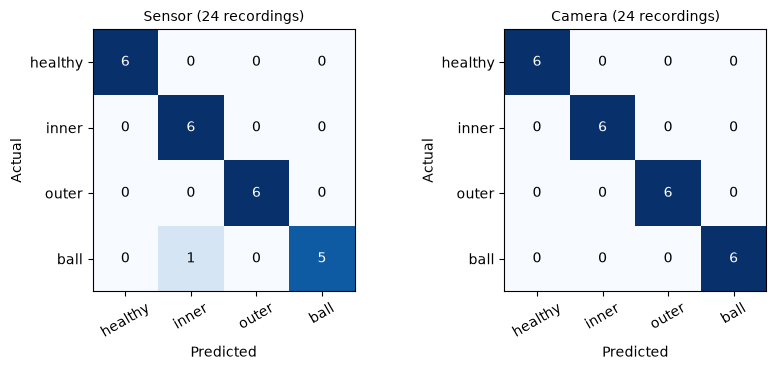

In [6]:
display(table({"Sensor: vibration": sensor, "Camera: event images": camera, "Camera: unseen set-up": camera_setup}))
show_matrices([("Sensor (24 recordings)", sensor["matrix"]), ("Camera (24 recordings)", camera["matrix"])], PUMP_CLASSES)

## Step 7 — Check against the saved results

The same numbers are stored in `Results/`. This confirms the notebook reproduces them.

In [7]:
saved = {}
rows = []
for label, mine, path in [
    ('Sensor', sensor, 'pump.json/sensor/random_forest_run_level'),
    ('Camera', camera, 'pump.json/camera/random_forest_run_level'),
    ('Camera, unseen set-up', camera_setup, 'pump.json/camera/held_out_camera_configuration_run_level'),
]:
    file, *keys = path.split('/')
    node = json.loads((RESULTS / file).read_text(encoding='utf-8'))
    for key in keys:
        node = node[key]
    same = all(round(node[k], 4) == mine[k] for k in ('accuracy', 'macro_precision', 'macro_recall', 'macro_f1'))
    rows.append({'result': label, 'this notebook': mine['accuracy'], 'saved result': round(node['accuracy'], 4),
                 'same': 'yes' if same else 'NO'})
display(pd.DataFrame(rows).set_index('result'))

,this notebook,saved result,same
result,,,
Sensor,0.9583,0.9583,yes
Camera,1.0000,1.0000,yes
"Camera, unseen set-up",0.8542,0.8542,yes


## What this means

- **Both work well here.** The sensor gets 23 of 24 test recordings right (0.958). The camera gets 24 of 24 (1.000). Guessing one class gets 0.250.
- **The camera's perfect score depends partly on the camera set-up.** When a set-up is never seen in training, it drops to about 0.85.
- **Not a winner contest.** The two branches use different lab rigs, so this does not show that cameras beat sensors.
- **Limits:** lab rigs, not mining pumps; it classifies the present condition, not when to repair.

Extra sensor-only pump checks (original pump XLSX, UCI hydraulic, ESPset) are saved in `Results/pump.json` and can be rerun with `python capstone_code.py uci-hydraulic`, `espset` or `pump-original-xlsx`; they have no camera branch.

**Data (CC BY 4.0):** University of Ottawa bearing vibration V2, DOI 10.17632/v43hmbwxpm.2; XJTU-DV, DOI 10.5281/zenodo.17447083.